# Week 6 · Task B — Three charts, three different questions
**Integration checkpoint · 5 marks**

| # | Question kind | Data | Decision it supports |
|---|---|---|---|
| 1 | **Trend** (time axis) | `grid_daily` → monthly energy by zone | When and where to size supply capacity |
| 2 | **Composition** (part-to-whole) | `generation_mix` parts | What the communications office may say about solar |
| 3 | **Relationship** | register: interruption rate vs income | Whether reliability money should follow income, not size |

Rules kept on every chart: finding in the title · zero baseline on bars · no second y-axis · colour that means something (checked with `vizlib.cvd_report`) · selective labels · source note · **every parameter that changed the picture is declared on the figure**. All three are drawn with `ax` methods and exported at 300 dpi.

> Run **Task A** first: this notebook reads only `clean/`.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

def find_root():
    """Folder that holds the three toolkits and data/ - works from week6/assignments or a copy of it."""
    here = Path.cwd().resolve()
    for base in [here, here / "assignments", here.parent, here.parent / "assignments"]:
        if (base / "vizlib.py").exists() and (base / "data").is_dir():
            return base
    raise FileNotFoundError("Open this notebook in the folder that contains vizlib.py, tslib.py, geolib.py and data/")

ROOT = find_root()
sys.path.insert(0, str(ROOT))
DATA, CLEAN = ROOT / "data", ROOT / "clean"
CLEAN.mkdir(exist_ok=True)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
import vizlib
from vizlib import PALETTE
vizlib.style_defaults()
need = ["district_grid.csv", "grid_monthly_energy.csv", "generation_parts.csv", "generation_total.csv"]
missing = [n for n in need if not (CLEAN / n).exists()]
assert not missing, f"Run Task_A_process.ipynb first - missing in clean/: {missing}"
print("clean files found:", need)

clean files found: ['district_grid.csv', 'grid_monthly_energy.csv', 'generation_parts.csv', 'generation_total.csv']


## Chart 1 — Trend: how much energy does each zone deliver per day, month by month?

*Parameters I chose, and declare on the figure:*
**aggregation** = monthly energy from the **change in the meter reading** (never `sum()` of the counter), shown as **mean MWh per day** so 28- and 31-day months compare fairly · **window** = Apr 2025 – Sep 2026 · **partial months** (Apr 2025 starts on 1 Apr, Sep 2026 has 11 days) drawn **hollow** · **P4 Feb 2026** is hollow-orange because one meter reset day is estimated · one panel per zone, **each with its own y-axis** (zones differ 5×; compare shape, not height) · 128 never-reported zone-days are left as gaps and monthly values straddle them by interpolating the *level*.

In [2]:
mm = pd.read_csv(CLEAN / "grid_monthly_energy.csv")
mm["m"] = pd.to_datetime(mm.month + "-01")
zones = sorted(mm.zone.unique())
full = mm[~mm.partial]

# numbers for the title come from the data, not from memory
peaks = full.loc[full.groupby("zone").mean_daily_mwh.idxmax()].set_index("zone").month
troughs = full.loc[full.groupby("zone").mean_daily_mwh.idxmin()].set_index("zone").month
yoy = []
for z in zones:
    g = mm[(mm.zone == z)].set_index("month").mean_daily_mwh
    yoy.append([g[f"2026-{k:02d}"] / g[f"2025-{k:02d}"] - 1 for k in (5, 6, 7, 8)])
yoy = np.array(yoy)
print("peak month by zone  :", peaks.to_dict())
print("trough month by zone:", troughs.to_dict())
print(f"same-month growth May-Aug 2026 vs 2025, by zone: {yoy.min():+.1%} .. {yoy.max():+.1%}")
assert peaks.nunique() == 1 and troughs.nunique() == 1
peak_name = pd.Timestamp(peaks.iloc[0] + "-01").strftime("%B"); trough_name = pd.Timestamp(troughs.iloc[0] + "-01").strftime("%B")

peak month by zone  : {'P1': '2026-07', 'P2': '2026-07', 'P3': '2026-07', 'P4': '2026-07', 'P5': '2026-07', 'P6': '2026-07'}
trough month by zone: {'P1': '2026-01', 'P2': '2026-01', 'P3': '2026-01', 'P4': '2026-01', 'P5': '2026-01', 'P6': '2026-01'}
same-month growth May-Aug 2026 vs 2025, by zone: +4.3% .. +8.2%


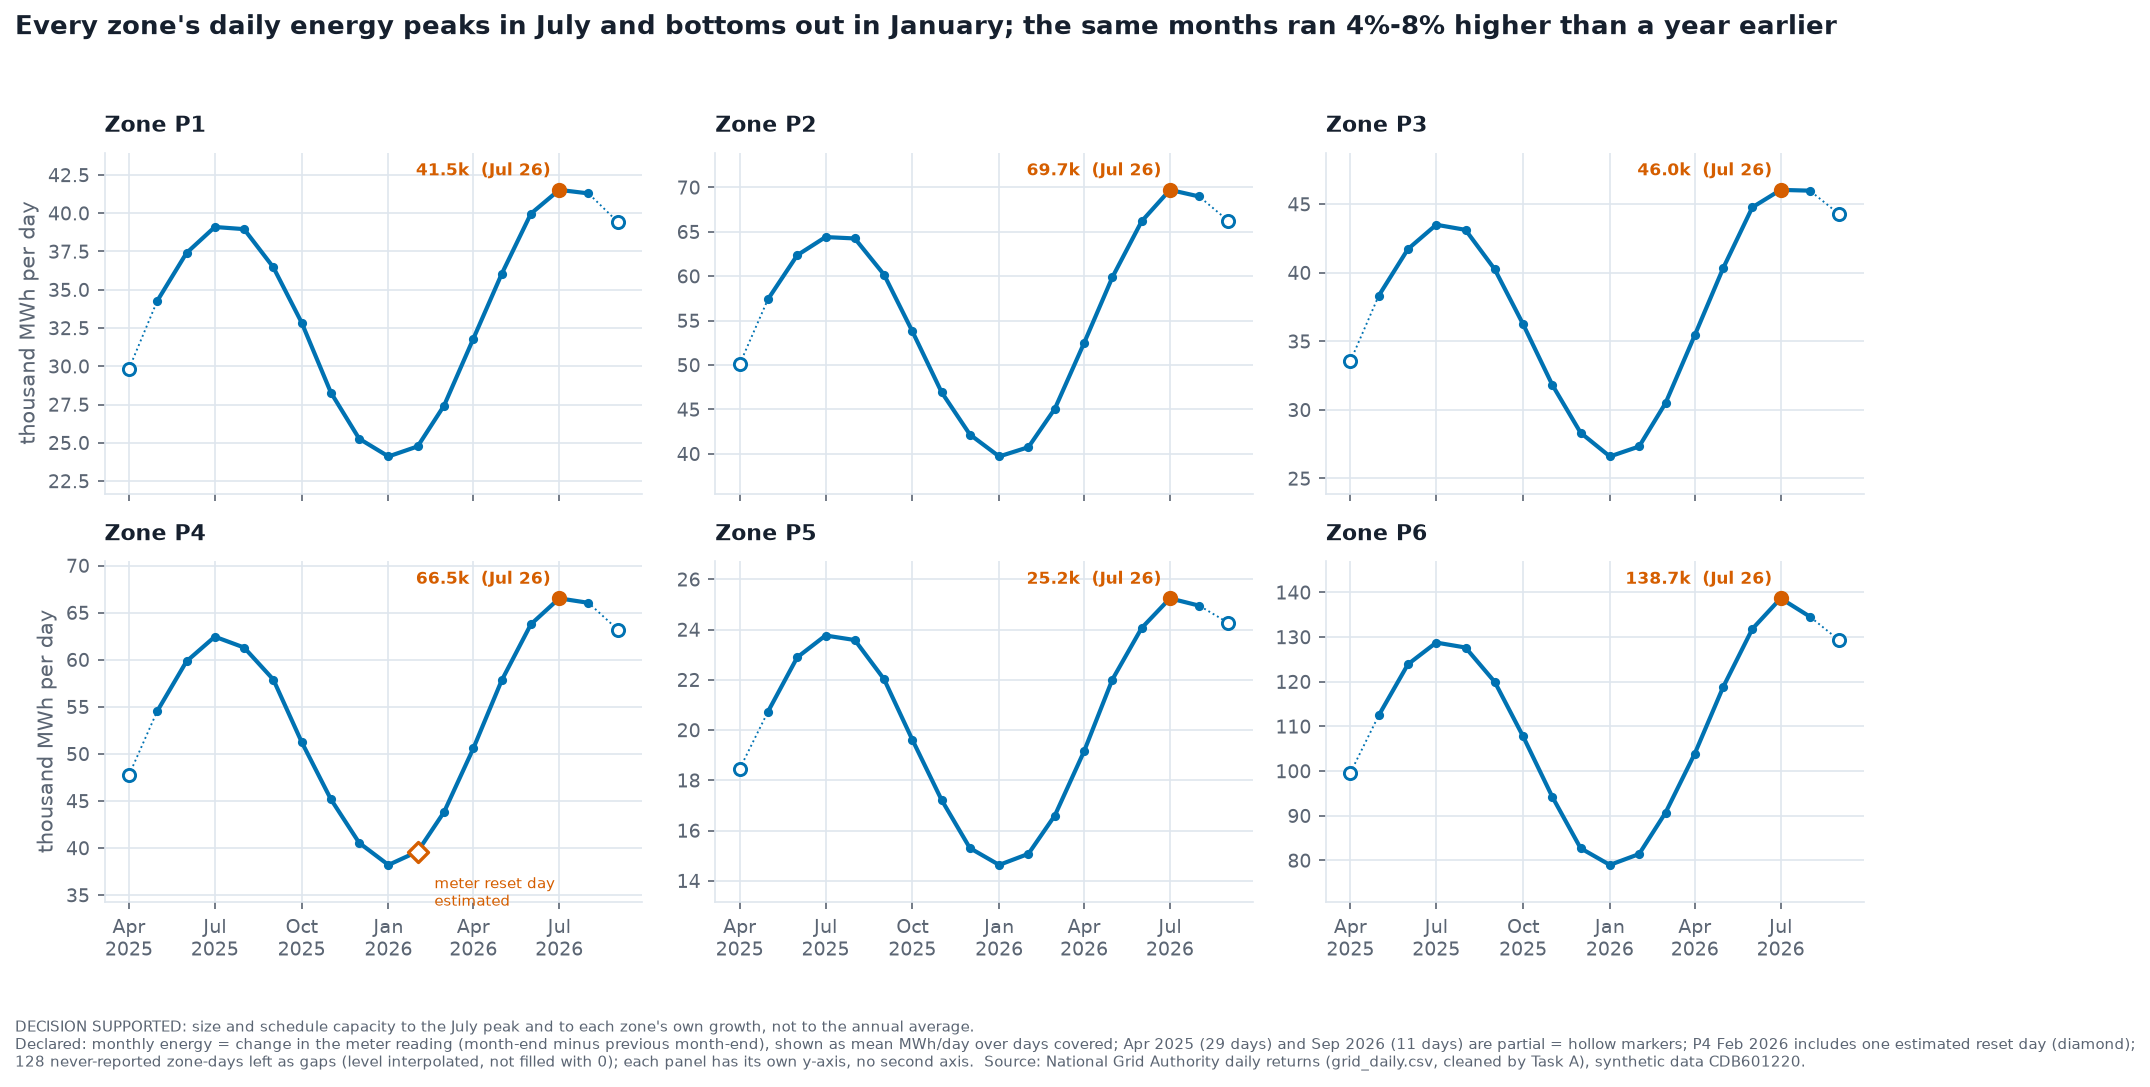

In [3]:
blue, orange, ink = PALETTE["series"][0], PALETTE["highlight"], PALETTE["ink_soft"]
fig, axes = plt.subplots(2, 3, figsize=(12.6, 6.6), sharex=True)
for ax, z in zip(axes.ravel(), zones):
    g = mm[mm.zone == z].sort_values("m")
    ax.plot(g.m, g.mean_daily_mwh / 1000, color=blue, lw=0.9, ls=":", zorder=1)                    # connects partial months
    f = g[~g.partial]
    ax.plot(f.m, f.mean_daily_mwh / 1000, color=blue, lw=2.0, marker="o", ms=3.4, zorder=2)
    p = g[g.partial]
    ax.scatter(p.m, p.mean_daily_mwh / 1000, s=34, facecolor="white", edgecolor=blue, lw=1.4, zorder=3)
    e = g[g.estimated]
    if len(e):
        ax.scatter(e.m, e.mean_daily_mwh / 1000, s=46, marker="D", facecolor="white", edgecolor=orange, lw=1.6, zorder=4)
        ax.annotate("meter reset day\nestimated", (e.m.iloc[0], e.mean_daily_mwh.iloc[0] / 1000), xytext=(8, -26),
                    textcoords="offset points", fontsize=7, color=orange)
    pk = f.loc[f.mean_daily_mwh.idxmax()]
    ax.scatter([pk.m], [pk.mean_daily_mwh / 1000], s=40, color=orange, zorder=5)               # selective label: the peak only
    ax.annotate(f"{pk.mean_daily_mwh/1000:.1f}k  ({pd.Timestamp(pk.m):%b %y})", (pk.m, pk.mean_daily_mwh / 1000),
                xytext=(-4, 7), textcoords="offset points", fontsize=8, color=orange, ha="right", fontweight="bold")
    ax.set_title(f"Zone {z}", fontsize=10.5)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    ax.margins(y=0.14)
for ax in axes[:, 0]: ax.set_ylabel("thousand MWh per day")
fig.suptitle(f"Every zone's daily energy peaks in {peak_name} and bottoms out in {trough_name}; "
             f"the same months ran {yoy.min():.0%}-{yoy.max():.0%} higher than a year earlier", x=0.01, ha="left", fontsize=12.5, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
note = ("DECISION SUPPORTED: size and schedule capacity to the July peak and to each zone's own growth, not to the annual average.\n"
        "Declared: monthly energy = change in the meter reading (month-end minus previous month-end), shown as mean MWh/day over days covered; Apr 2025 (29 days) and Sep 2026 (11 days) are partial = hollow markers; "
        "P4 Feb 2026 includes one estimated reset day (diamond);\n128 never-reported zone-days left as gaps (level interpolated, not filled with 0); each panel has its own y-axis, no second axis.  "
        "Source: National Grid Authority daily returns (grid_daily.csv, cleaned by Task A), synthetic data CDB601220.")
vizlib.save_fig(fig, ROOT / "partB_1.png", note=note)
plt.show()

## Chart 2 — Composition: is the shift to renewables real, or arithmetic?

Both statements are true at once: total generation is **down 5.0 %** while solar is **up 82.1 % in MWh** and **4.1 % → 7.9 % of the mix**. A share without the direction of its total is how the second sentence gets quoted alone, so this chart draws **MWh** (absolute, zero baseline) and prints the total beside the share.

*Parameters:* all 18 months · the **144 part rows only** (the published `All sources / Total` row is excluded — it is a whole, not a part) · five exclusive categories, **no “Other” bucket** · nothing else excluded.

In [4]:
parts = pd.read_csv(CLEAN / "generation_parts.csv"); tot = pd.read_csv(CLEAN / "generation_total.csv").set_index("month").total_mwh
parts["cat"] = parts.subsource.where(parts.source.isin(["Renewable"]), parts.source)          # Solar / Wind separate, others by source
order = ["Fossil", "Hydro", "Imported", "Wind", "Solar"]
wide = parts.groupby(["month", "cat"]).mwh.sum().unstack()[order]
assert (wide.sum(axis=1) - tot).abs().max() <= 2                                               # exclusive & complete
a, b = wide.index[0], wide.index[-1]
d_tot, d_solar = tot[b] / tot[a] - 1, wide.Solar[b] / wide.Solar[a] - 1
sh_a, sh_b = wide.Solar[a] / tot[a], wide.Solar[b] / tot[b]
print(f"total {tot[a]/1e6:.2f} -> {tot[b]/1e6:.2f} TWh ({d_tot:+.1%}); solar {d_solar:+.1%} MWh; share {sh_a:.1%} -> {sh_b:.1%}")
colors = {"Fossil": PALETTE["ink_soft"], "Hydro": PALETTE["series"][0], "Imported": PALETTE["muted"], "Wind": PALETTE["series"][2], "Solar": PALETTE["highlight"]}
_ = vizlib.cvd_report(list(colors.values()), "deutan")
print("worst pair (deutan):", vizlib.worst_pair(list(colors.values()), "deutan"))

total 11.05 -> 10.49 TWh (-5.0%); solar +82.1% MWh; share 4.1% -> 7.9%
deutan simulation
  #5B6573  ->  #5E6373
  #0072B2  ->  #3B67B1
  #9AA7B4  ->  #9FA4B4
  #009E73  ->  #8A8676
  #D55E00  ->  #9E8C00
worst pair (deutan): (1, 2, '#5B6573', '#0072B2', 10.32316691946393)


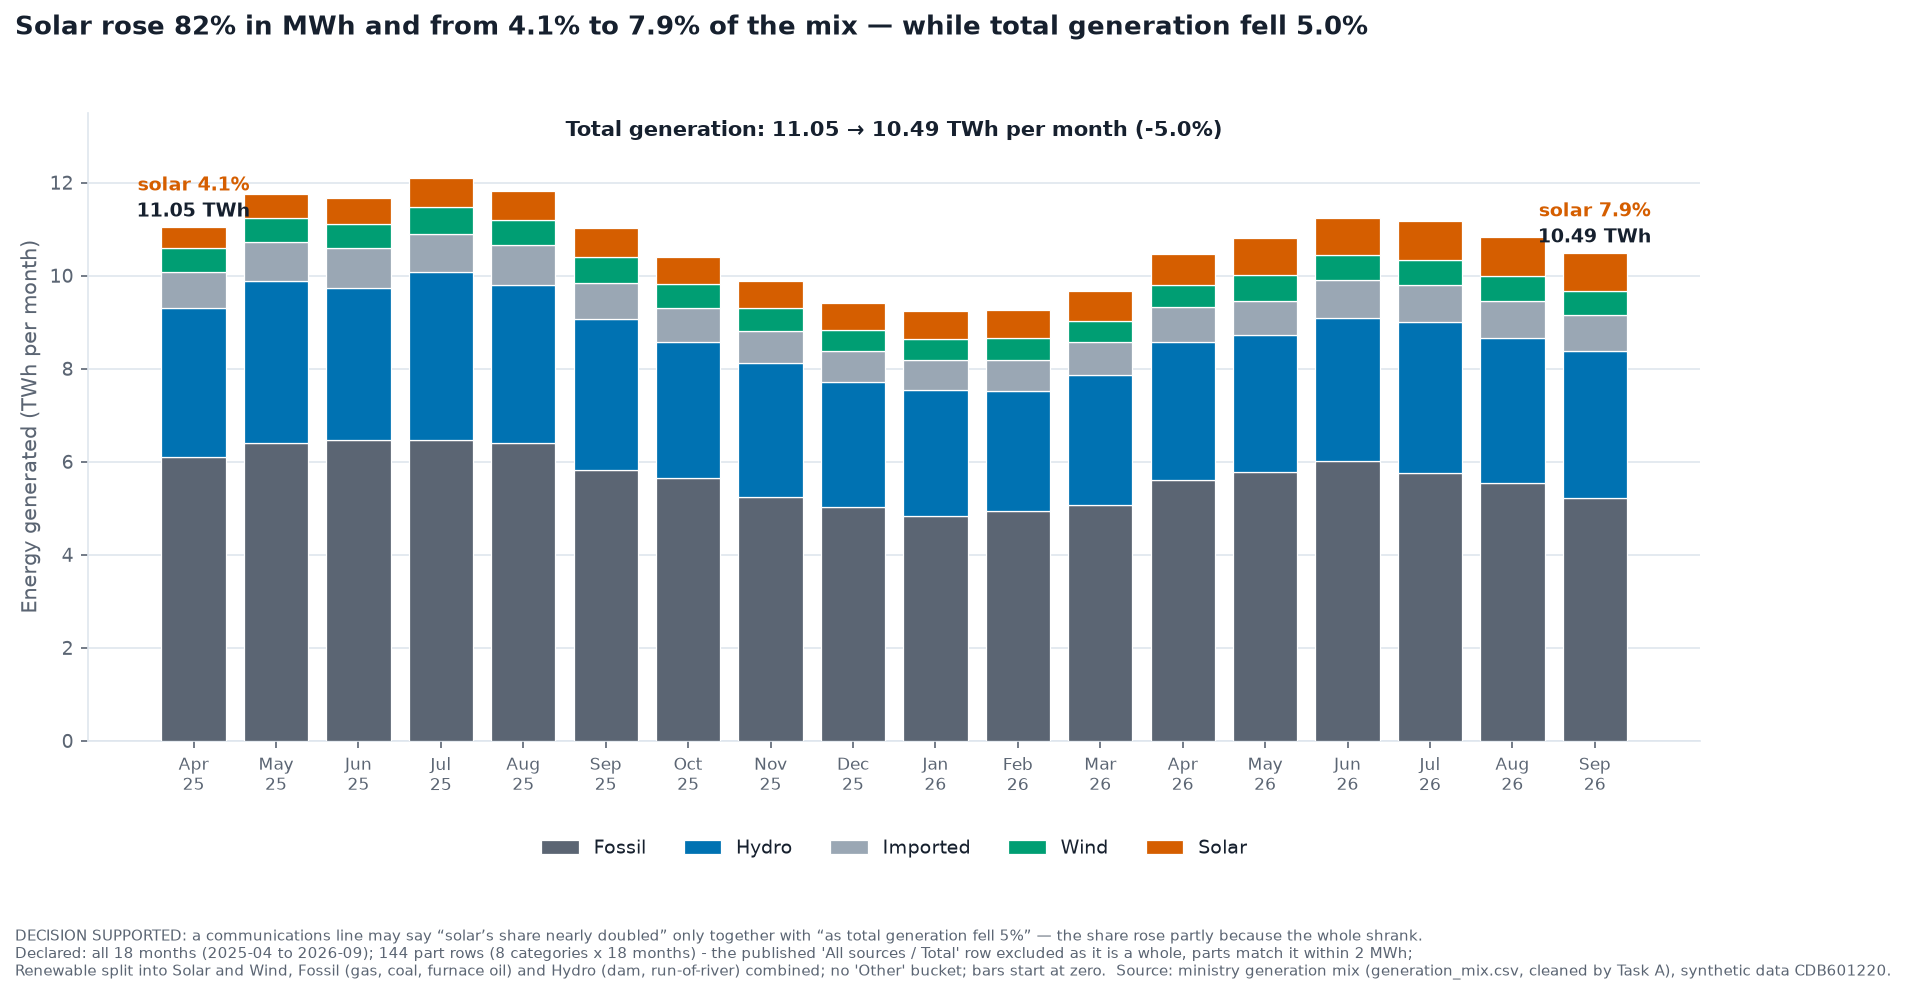

In [5]:
fig, ax = plt.subplots(figsize=(11.5, 6.0))
x = np.arange(len(wide)); bottom = np.zeros(len(wide))
for cat in order:
    ax.bar(x, wide[cat] / 1e6, bottom=bottom, width=0.78, color=colors[cat], edgecolor="white", lw=0.6, label=cat, zorder=3)
    bottom += (wide[cat] / 1e6).to_numpy()
ax.set_xticks(x); ax.set_xticklabels([pd.Timestamp(m + "-01").strftime("%b\n%y") for m in wide.index], fontsize=8)
ax.set_ylim(0, 13.5); ax.set_ylabel("Energy generated (TWh per month)")
# selective labels: first and last month only - total (and its direction) plus the solar share
for i, m in [(0, a), (len(wide) - 1, b)]:
    ax.text(i, tot[m] / 1e6 + 0.22, f"{tot[m]/1e6:.2f} TWh", ha="center", fontsize=9, fontweight="bold", color=PALETTE["ink"])
    ax.text(i, tot[m] / 1e6 + 0.78, f"solar {wide.Solar[m]/tot[m]:.1%}", ha="center", fontsize=9, fontweight="bold", color=PALETTE["highlight"])
ax.text(8.5, 13.0, f"Total generation: {tot[a]/1e6:.2f} → {tot[b]/1e6:.2f} TWh per month ({d_tot:+.1%})", ha="center", fontsize=10, fontweight="bold", color=PALETTE["ink"])
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.13), fontsize=9)
ax.grid(axis="x", visible=False)
fig.suptitle(f"Solar rose {d_solar:.0%} in MWh and from {sh_a:.1%} to {sh_b:.1%} of the mix \u2014 while total generation fell {abs(d_tot):.1%}",
             x=0.01, ha="left", fontsize=12.5, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
note = ("DECISION SUPPORTED: a communications line may say \u201csolar\u2019s share nearly doubled\u201d only together with \u201cas total generation fell 5%\u201d \u2014 the share rose partly because the whole shrank.\n"
        "Declared: all 18 months (2025-04 to 2026-09); 144 part rows (8 categories x 18 months) - the published 'All sources / Total' row excluded as it is a whole, parts match it within 2 MWh;\n"
        "Renewable split into Solar and Wind, Fossil (gas, coal, furnace oil) and Hydro (dam, run-of-river) combined; no 'Other' bucket; bars start at zero.  "
        "Source: ministry generation mix (generation_mix.csv, cleaned by Task A), synthetic data CDB601220.")
vizlib.save_fig(fig, ROOT / "partB_2.png", note=note)
plt.show()

## Chart 3 — Relationship: does interruption rate follow income?

*Parameters:* y = interruptions per **1,000 households** (the denominator is named, not left to the reader) · x = income per head (USD/year) · bubble **area** ∝ households, with a size legend · n = 24 districts (D11 de-duplicated, D21 households repaired in Task A) · ordinary least-squares line with Pearson r, a description of these 24 points, **not** a causal claim · reference line = national pooled rate (Σ interruptions ÷ Σ households).

n=24  r(rate, income) = -0.71  slope -1.95 per +USD 1,000  pooled 43.7


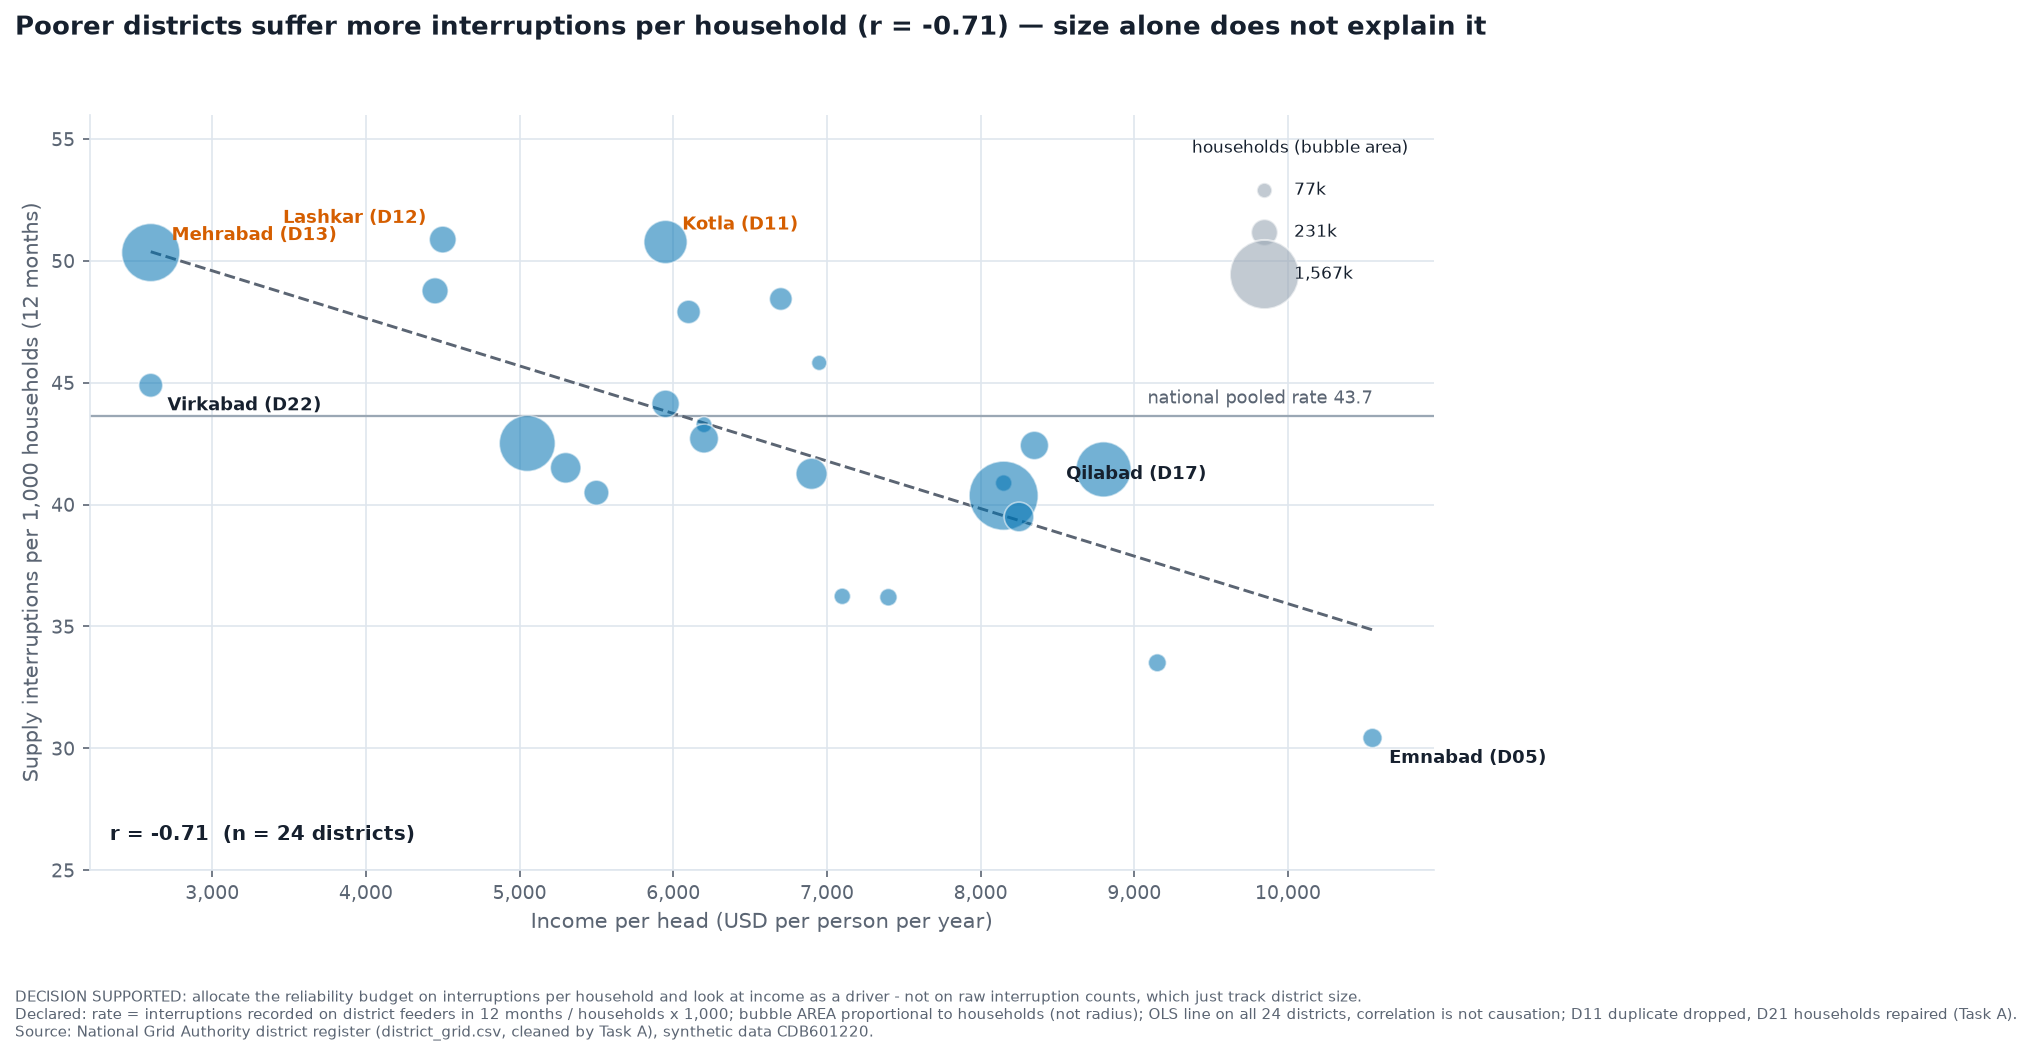

In [6]:
reg = pd.read_csv(CLEAN / "district_grid.csv")
pooled = reg.outages.sum() / reg.households.sum() * 1000
r_inc = np.corrcoef(reg.income_pc_usd, reg.interruptions_per_1000_hh)[0, 1]
slope, icpt = np.polyfit(reg.income_pc_usd, reg.interruptions_per_1000_hh, 1)
print(f"n={len(reg)}  r(rate, income) = {r_inc:.2f}  slope {slope*1000:.2f} per +USD 1,000  pooled {pooled:.1f}")

fig, ax = plt.subplots(figsize=(10.5, 6.4))
size = 1100 * reg.households / reg.households.max()
ax.scatter(reg.income_pc_usd, reg.interruptions_per_1000_hh, s=size, color=PALETTE["series"][0], alpha=0.55, edgecolor="white", lw=0.8, zorder=3)
xs = np.linspace(reg.income_pc_usd.min(), reg.income_pc_usd.max(), 50)
ax.plot(xs, icpt + slope * xs, color=PALETTE["ink_soft"], lw=1.4, ls="--", zorder=2)
ax.axhline(pooled, color=PALETTE["muted"], lw=1.1, zorder=1)
ax.text(reg.income_pc_usd.max(), pooled + 0.5, f"national pooled rate {pooled:.1f}", ha="right", fontsize=8.5, color=PALETTE["ink_soft"])
lab = {"D13": (10, 6), "D12": (-8, 8), "D11": (8, 6), "D22": (8, -12), "D05": (8, -12), "D17": (30, 8)}
for c, off in lab.items():
    r = reg[reg.code == c].iloc[0]
    ax.annotate(f"{r.district} ({c})", (r.income_pc_usd, r.interruptions_per_1000_hh), xytext=off, textcoords="offset points",
                fontsize=8.5, fontweight="bold", color=PALETTE["highlight"] if c in ("D13", "D12", "D11") else PALETTE["ink"],
                ha="right" if off[0] < 0 else "left")
ax.text(0.015, 0.04, f"r = {r_inc:.2f}  (n = 24 districts)", transform=ax.transAxes, fontsize=9.5, fontweight="bold")
ax.set_xlabel("Income per head (USD per person per year)"); ax.set_ylabel("Supply interruptions per 1,000 households (12 months)")
ax.set_ylim(25, 56); ax.xaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
h = [ax.scatter([], [], s=1100 * v / reg.households.max(), color=PALETTE["muted"], alpha=0.6, edgecolor="white") for v in (reg.households.min(), reg.households.median(), reg.households.max())]
ax.legend(h, [f"{v/1e3:,.0f}k" for v in (reg.households.min(), reg.households.median(), reg.households.max())], title="households (bubble area)",
          loc="upper right", labelspacing=1.5, borderpad=1.0, fontsize=8, title_fontsize=8)
fig.suptitle(f"Poorer districts suffer more interruptions per household (r = {r_inc:.2f}) \u2014 size alone does not explain it",
             x=0.01, ha="left", fontsize=12.5, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
note = ("DECISION SUPPORTED: allocate the reliability budget on interruptions per household and look at income as a driver - not on raw interruption counts, which just track district size.\n"
        "Declared: rate = interruptions recorded on district feeders in 12 months / households x 1,000; bubble AREA proportional to households (not radius); OLS line on all 24 districts, correlation is not causation; "
        "D11 duplicate dropped, D21 households repaired (Task A).\nSource: National Grid Authority district register (district_grid.csv, cleaned by Task A), synthetic data CDB601220.")
vizlib.save_fig(fig, ROOT / "partB_3.png", note=note)
plt.show()

## Self-check against the brief

| Requirement | Where it is met |
|---|---|
| Three different question kinds, chart fits each | Trend (lines on a real time axis) · Composition (stacked bars, parts only) · Relationship (scatter, size legend) |
| ≥1 chart on `grid_daily` with a time axis; ≥1 on `generation_mix` as part-to-whole | Charts 1 and 2 |
| Finding in the title · zero-baseline bars · no second y-axis · meaningful colour · selective labels · source note | all three; Chart 2 palette passes `vizlib.cvd_report` / `worst_pair` |
| Every parameter that changed the picture is declared on the figure | footnote block under each figure (aggregation, window, partial periods, excluded rows, bucket choice) |
| Anchors | generation −5.0 %, solar +82.1 % in MWh and 4.1 % → 7.9 % of the mix (printed above) |